# Hyperparameter Tuning Task: CarShield AI Autoencoder

In [4]:
!pip install -q keras==3.15.1

## Import Libraries

In [5]:
import os, json
import numpy as np
import pandas as pd
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, regularizers
import matplotlib.pyplot as plt

SEED = 42
tf.keras.utils.set_random_seed(SEED)

for folder in ["models", "results/plots", "configs"]:
    os.makedirs(folder, exist_ok=True)

## Load the Dataset

In [6]:
x_train = pd.read_parquet("train_scaled.parquet").values.astype("float32")
x_val = pd.read_parquet("validation_scaled.parquet").values.astype("float32")

print(x_train.shape, x_val.shape)

(791096, 10) (197775, 10)


## Task 1: Baseline Model


In [7]:
baseline_model = keras.models.load_model("baseline_autoencoder.keras")

def val_loss(model):
    pred = model.predict(x_val, batch_size=4096, verbose=0)
    return float(np.mean((x_val - pred) ** 2))

baseline_loss = val_loss(baseline_model)
print("Baseline val_loss:", round(baseline_loss, 6))

Baseline val_loss: 0.008027


## Build the Model


In [8]:
def build_model(hidden=[8, 4, 8], lr=0.001, l2=0.0, dropout=0.0):
    tf.keras.utils.set_random_seed(SEED)
    reg = regularizers.l2(l2)

    model = keras.Sequential([layers.Input(shape=(10,))])
    for units in hidden:
        model.add(layers.Dense(units, activation="relu", kernel_regularizer=reg))
        if dropout > 0 and units != min(hidden):
            model.add(layers.Dropout(dropout))
    model.add(layers.Dense(10, activation="sigmoid"))

    model.compile(optimizer=keras.optimizers.Adam(learning_rate=lr), loss="mse")
    return model

# Check: our default model must have the same size as the baseline (254 parameters)
print("Baseline params:", baseline_model.count_params(), "| our params:", build_model().count_params())

Baseline params: 254 | our params: 254


## Early Stopping


In [9]:
# Early Stopping: stop when val_loss stops improving, and keep the best epoch.
# A function, because every experiment needs a fresh copy.
def early_stop():
    return keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=10,
        min_delta=0.00001,
        restore_best_weights=True,
    )

results = []     # one row per experiment -> final results table
models = {}      # trained model of each experiment
histories = {}   # training curve of each experiment (for plots)

## Task 2: Reproduce the Baseline + Add Early Stopping
- **E01:** same as the baseline (20 epochs, no Early Stopping). Should give ≈ 0.0080.
- **E02:** only change: Early Stopping with up to 100 epochs.

In [10]:
#E01:
# Goal: prove our code gives the same result as the baseline (≈ 0.0080)

model = build_model()
h01 = model.fit(x_train, x_train,
                validation_data=(x_val, x_val),
                epochs=20, batch_size=256, verbose=0)
loss = val_loss(model)

results.append({"ID": "E01", "Architecture": "8-4-8", "LR": 0.001, "Batch": 256,
                "Regularization": "None", "Val Loss": loss, "Epochs": 20,
                "Params": model.count_params(), "Notes": "Reproduce baseline"})
models["E01"] = model
histories["E01"] = h01.history
print("E01 val_loss:", round(loss, 6))


#E02:
# Hypothesis: val_loss was still falling at epoch 20, so longer training will lower it

model = build_model()
h02 = model.fit(x_train, x_train,
                validation_data=(x_val, x_val),
                epochs=100, batch_size=256,
                callbacks=[early_stop()], verbose=0)
loss = val_loss(model)
epochs_run = len(h02.history["loss"])                          # how many epochs before it stopped

# 4) record the result
results.append({"ID": "E02", "Architecture": "8-4-8", "LR": 0.001, "Batch": 256,
                "Regularization": "EarlyStopping", "Val Loss": loss, "Epochs": epochs_run,
                "Params": model.count_params(), "Notes": "val_loss still falling at epoch 20 -> train longer"})
models["E02"] = model
histories["E02"] = h02.history
print("E02 val_loss:", round(loss, 6), "| stopped after", epochs_run, "epochs")

E01 val_loss: 0.00803
E02 val_loss: 0.007725 | stopped after 52 epochs


## Task 3: Tune Learning Rate
The baseline used 0.001. Try 3× bigger (0.003) and 3× smaller (0.0003).

In [11]:
lr_results = {0.001: results[-1]["Val Loss"]}      # results[-1] = last row added = E02

# Each experiment: (experiment name, learning rate to try, hypothesis)
lr_experiments = [
    ("E03", 0.003,  "Bigger LR: may get past the slow phase (epochs 6-10) faster"),
    ("E04", 0.0003, "Smaller LR: slower but smoother learning"),
]

for exp_id, lr, note in lr_experiments:
    print(f"\nTraining {exp_id} with learning rate = {lr}")

    model = build_model(lr=lr)
    h = model.fit(x_train, x_train,
                  validation_data=(x_val, x_val),
                  epochs=100, batch_size=256,
                  callbacks=[early_stop()], verbose=0)
    loss = val_loss(model)
    epochs_run = len(h.history["loss"])

    #record the result
    results.append({"ID": exp_id, "Architecture": "8-4-8", "LR": lr, "Batch": 256,
                    "Regularization": "EarlyStopping", "Val Loss": loss, "Epochs": epochs_run,
                    "Params": model.count_params(), "Notes": note})
    models[exp_id] = model
    histories[exp_id] = h.history
    lr_results[lr] = loss                                      # keep for choosing the best LR

    print("Val loss:", round(loss, 6), "| stopped after", epochs_run, "epochs")

# Choose the learning rate with the lowest val loss -> used in all next tasks
best_lr = min(lr_results, key=lr_results.get)
print("\nAll LR results:", lr_results)
print("Best learning rate:", best_lr)


Training E03 with learning rate = 0.003
Val loss: 0.006 | stopped after 48 epochs

Training E04 with learning rate = 0.0003
Val loss: 0.006834 | stopped after 67 epochs

All LR results: {0.001: 0.007724680006504059, 0.003: 0.006000251974910498, 0.0003: 0.006834013853222132}
Best learning rate: 0.003


## Task 4: Tune Batch Size
The baseline used 256. Try half (128) and double (512), with the best learning rate.

In [12]:
# Batch 256 with the best LR was already trained in Task 3, so we reuse its result
batch_results = {256: lr_results[best_lr]}

# Each experiment: (experiment name, batch size to try, hypothesis)
batch_experiments = [
    ("E05", 128, "Smaller batch: more weight updates per epoch, may learn finer details"),
    ("E06", 512, "Bigger batch: faster and smoother training, maybe similar loss"),
]

for exp_id, batch, note in batch_experiments:
    print(f"\nTraining {exp_id} with batch size = {batch}")

    model = build_model(lr=best_lr)
    h = model.fit(x_train, x_train,
                  validation_data=(x_val, x_val),
                  epochs=100, batch_size=batch,
                  callbacks=[early_stop()], verbose=0)
    loss = val_loss(model)
    epochs_run = len(h.history["loss"])

    # record the result
    results.append({"ID": exp_id, "Architecture": "8-4-8", "LR": best_lr, "Batch": batch,
                    "Regularization": "EarlyStopping", "Val Loss": loss, "Epochs": epochs_run,
                    "Params": model.count_params(), "Notes": note})
    models[exp_id] = model
    histories[exp_id] = h.history
    batch_results[batch] = loss                         # keep for choosing the best batch

    print("Val loss:", round(loss, 6), "| stopped after", epochs_run, "epochs")

# Choose the batch size with the lowest val loss -> used in all next tasks
best_batch = min(batch_results, key=batch_results.get)
print("\nAll batch results:", batch_results)
print("Best batch size:", best_batch)


Training E05 with batch size = 128
Val loss: 0.008397 | stopped after 25 epochs

Training E06 with batch size = 512
Val loss: 0.008024 | stopped after 38 epochs

All batch results: {256: 0.006000251974910498, 128: 0.008397324942052364, 512: 0.008023755624890327}
Best batch size: 256


## Task 5: Tune Layer Sizes
Baseline: 8-4-8. The middle layer (bottleneck) stays **4** in all experiments; only the width and depth change.
If the middle layer gets close to 10 (the number of features), the model just copies the input and cannot detect attacks.

In [13]:
# 8-4-8 with the best LR and batch was already trained, so we reuse its result
arch_results = {"8-4-8": batch_results[best_batch]}

# Each experiment: (experiment name, hidden layers, hypothesis)
arch_experiments = [
    ("E07", [6, 4, 6],         "Narrower: 8-4-8 may be bigger than needed"),
    ("E08", [16, 4, 16],       "Wider: more units may capture more patterns"),
    ("E09", [16, 8, 4, 8, 16], "Deeper: more gradual compression may help"),
]
for exp_id, hidden, note in arch_experiments:
    name = "-".join(map(str, hidden))                  # [16, 4, 16] -> "16-4-16"
    print(f"\nTraining {exp_id} with layers = {name}")

    model = build_model(hidden=hidden, lr=best_lr)     # only the layers change
    h = model.fit(x_train, x_train,
                  validation_data=(x_val, x_val),
                  epochs=100, batch_size=best_batch,
                  callbacks=[early_stop()], verbose=0)
    loss = val_loss(model)
    epochs_run = len(h.history["loss"])

    # record the result
    results.append({"ID": exp_id, "Architecture": name, "LR": best_lr, "Batch": best_batch,
                    "Regularization": "EarlyStopping", "Val Loss": loss, "Epochs": epochs_run,
                    "Params": model.count_params(), "Notes": note})
    models[exp_id] = model
    histories[exp_id] = h.history
    arch_results[name] = loss                          # keep for choosing the best layers

    print("Val loss:", round(loss, 6), "| params:", model.count_params(), "| stopped after", epochs_run, "epochs")

# Choose the layers with the lowest val loss -> used in the next task
best_arch = min(arch_results, key=arch_results.get)
best_hidden = [int(u) for u in best_arch.split("-")]  # "16-4-16" -> [16, 4, 16]
print("\nAll layer results:", arch_results)
print("Best layers:", best_arch)


Training E07 with layers = 6-4-6
Val loss: 0.014383 | params: 194 | stopped after 47 epochs

Training E08 with layers = 16-4-16
Val loss: 0.003973 | params: 494 | stopped after 48 epochs

Training E09 with layers = 16-8-4-8-16
Val loss: 0.00213 | params: 702 | stopped after 39 epochs

All layer results: {'8-4-8': 0.006000251974910498, '6-4-6': 0.01438253652304411, '16-4-16': 0.003972593694925308, '16-8-4-8-16': 0.002130253706127405}
Best layers: 16-8-4-8-16


## Task 6: L2 and Dropout
Applied to the best model so far (best layers, best LR, best batch).

**L2 values** come from the baseline model: L2 adds λ × (sum of squared weights) to the loss.
We pick λ so this extra penalty is about **1%** and **10%** of the baseline loss.

In [14]:
# Sum of squared weights in the baseline model
sum_sq = 0
for layer in baseline_model.layers:
    weights = layer.get_weights()[0]
    sum_sq += np.sum(weights ** 2)

# L2 so the penalty ≈ 1% and 10% of the baseline loss
l2_small = float(f"{0.01 * baseline_loss / sum_sq:.0e}")
l2_large = float(f"{0.10 * baseline_loss / sum_sq:.0e}")

print("L2 values to try:", np.format_float_positional(l2_small), np.format_float_positional(l2_large))

L2 values to try: 0.0000001 0.000001


In [16]:
best_before_reg = arch_results[best_arch]

reg_experiments = [
    ("E10", l2_small, 0.0, "Light L2: may help generalization"),
    ("E11", l2_large, 0.0, "Stronger L2: may underfit"),
    ("E12", 0.0,      0.1, "Dropout 0.1: small network, probably no help"),
]

for exp_id, l2, dropout, note in reg_experiments:
    if l2 > 0:
        reg_name = f"ES + L2 {np.format_float_positional(l2)}"
    else:
        reg_name = f"ES + Dropout {dropout}"
    print(f"\nTraining {exp_id} with {reg_name}")

    model = build_model(hidden=best_hidden, lr=best_lr, l2=l2, dropout=dropout)
    h = model.fit(x_train, x_train,
                  validation_data=(x_val, x_val),
                  epochs=100, batch_size=best_batch,
                  callbacks=[early_stop()], verbose=0)
    loss = val_loss(model)
    epochs_run = len(h.history["loss"])

    results.append({"ID": exp_id, "Architecture": best_arch, "LR": best_lr, "Batch": best_batch,
                    "Regularization": reg_name, "Val Loss": loss, "Epochs": epochs_run,
                    "Params": model.count_params(), "Notes": note})
    models[exp_id] = model
    histories[exp_id] = h.history

    print("Val loss:", round(loss, 6), "| before:", round(best_before_reg, 6),
          "| better?", loss < best_before_reg)


Training E10 with ES + L2 0.0000001
Val loss: 0.003316 | before: 0.00213 | better? False

Training E11 with ES + L2 0.000001
Val loss: 0.00485 | before: 0.00213 | better? False

Training E12 with ES + Dropout 0.1
Val loss: 0.013406 | before: 0.00213 | better? False


## Final Comparison

In [17]:
results_df = pd.DataFrame(results)
results_df.to_csv("results/tuning_results.csv", index=False)
display(results_df)

# Selection rule: lowest val loss, but simplest model if within 2%
lowest = results_df["Val Loss"].min()
close = results_df[results_df["Val Loss"] <= lowest * 1.02]
best = close.sort_values(["Params", "Val Loss"]).iloc[0]

print("Lowest val_loss:", round(lowest, 6))
print("Within 2%:", list(close["ID"]))
print("Chosen (simplest):", best["ID"], "| params:", best["Params"])

print("\nBaseline val_loss:", round(baseline_loss, 6))
print("Best model:", best["ID"], "| val_loss:", round(best["Val Loss"], 6))
print("Difference:", round(baseline_loss - best["Val Loss"], 6))
print(f"Improvement: {(baseline_loss - best['Val Loss']) / baseline_loss * 100:.1f}%")

,ID,Architecture,LR,Batch,Regularization,Val Loss,Epochs,Params,Notes
0,E01,8-4-8,0.0010,256,None,0.008030,20,254,Reproduce baseline
1,E02,8-4-8,0.0010,256,EarlyStopping,0.007725,52,254,val_loss still falling at epoch 20 -> train lo...
2,E03,8-4-8,0.0030,256,EarlyStopping,0.006000,48,254,Bigger LR: may get past the slow phase (epochs...
3,E04,8-4-8,0.0003,256,EarlyStopping,0.006834,67,254,Smaller LR: slower but smoother learning
4,E05,8-4-8,0.0030,128,EarlyStopping,0.008397,25,254,"Smaller batch: more weight updates per epoch, ..."
5,E06,8-4-8,0.0030,512,EarlyStopping,0.008024,38,254,"Bigger batch: faster and smoother training, ma..."
6,E07,6-4-6,0.0030,256,EarlyStopping,0.014383,47,194,Narrower: 8-4-8 may be bigger than needed
7,E08,16-4-16,0.0030,256,EarlyStopping,0.003973,48,494,Wider: more units may capture more patterns
8,E09,16-8-4-8-16,0.0030,256,EarlyStopping,0.002130,39,702,Deeper: more gradual compression may help
9,E10,16-8-4-8-16,0.0030,256,ES + L2 0.0000001,0.003316,21,702,Light L2: may help generalization


Lowest val_loss: 0.00213
Within 2%: ['E09']
Chosen (simplest): E09 | params: 702

Baseline val_loss: 0.008027
Best model: E09 | val_loss: 0.00213
Difference: 0.005897
Improvement: 73.5%


## Save the Best Model

In [18]:
best_model = models[best["ID"]]
best_model.save("models/best_ae.keras")

best_config = {
    "experiment_id": best["ID"],
    "architecture": best["Architecture"],
    "learning_rate": float(best["LR"]),
    "batch_size": int(best["Batch"]),
    "regularization": best["Regularization"],
    "early_stopping": {"monitor": "val_loss", "patience": 10, "min_delta": 0.00001},
    "epochs_run": int(best["Epochs"]),
    "val_loss": float(best["Val Loss"]),
    "baseline_val_loss": baseline_loss,
    "selection_rule": "lowest val_loss; simplest model if within 2%",
    "seed": SEED,
}
with open("configs/best_config.json", "w") as f:
    json.dump(best_config, f, indent=2)

print(best_config)

# Check: the saved file opens and gives the same val_loss
reloaded = keras.models.load_model("models/best_ae.keras")
print("Reloaded val_loss:", round(val_loss(reloaded), 6))

{'experiment_id': 'E09', 'architecture': '16-8-4-8-16', 'learning_rate': 0.003, 'batch_size': 256, 'regularization': 'EarlyStopping', 'early_stopping': {'monitor': 'val_loss', 'patience': 10, 'min_delta': 1e-05}, 'epochs_run': 39, 'val_loss': 0.002130253706127405, 'baseline_val_loss': 0.008027410134673119, 'selection_rule': 'lowest val_loss; simplest model if within 2%', 'seed': 42}
Reloaded val_loss: 0.00213


## Plots

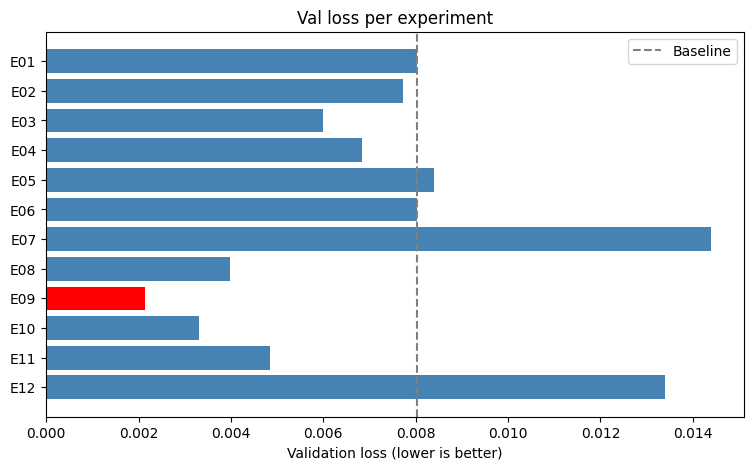

In [19]:
# 1) Val loss of every experiment (chosen model in red)
colors = ["red" if exp_id == best["ID"] else "steelblue" for exp_id in results_df["ID"]]

plt.figure(figsize=(9, 5))
plt.barh(results_df["ID"], results_df["Val Loss"], color=colors)
plt.axvline(baseline_loss, color="gray", linestyle="--", label="Baseline")
plt.xlabel("Validation loss (lower is better)")
plt.title("Val loss per experiment")
plt.gca().invert_yaxis()
plt.legend()
plt.savefig("results/plots/tuning_val_loss.png", dpi=150, bbox_inches="tight")
plt.show()

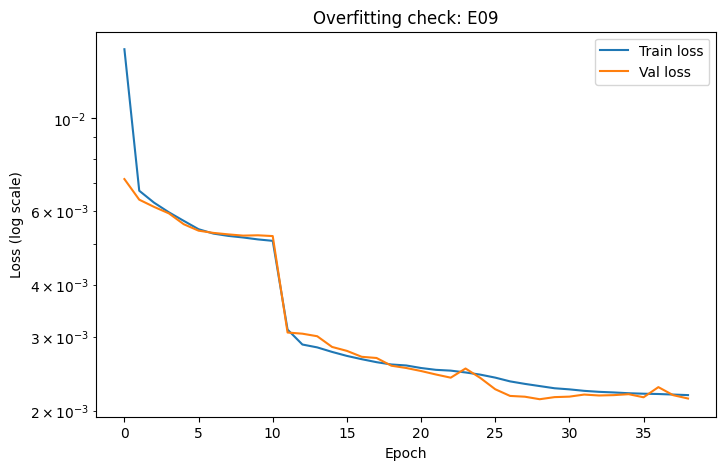

Train loss: 0.002278
Val loss:   0.00213
Gap: -6.5%
No overfitting: train and val loss are close


In [20]:
# 2) Overfitting check: train loss vs val loss of the best model
h = histories[best["ID"]]

plt.figure(figsize=(8, 5))
plt.plot(h["loss"], label="Train loss")
plt.plot(h["val_loss"], label="Val loss")
plt.yscale("log")
plt.xlabel("Epoch")
plt.ylabel("Loss (log scale)")
plt.title(f"Overfitting check: {best['ID']}")
plt.legend()
plt.savefig("results/plots/overfitting_check.png", dpi=150, bbox_inches="tight")
plt.show()

# Loss on the full train set vs val set (final weights)
train_loss = float(np.mean((x_train - best_model.predict(x_train, batch_size=4096, verbose=0)) ** 2))
val_loss_best = val_loss(best_model)
gap = (val_loss_best - train_loss) / train_loss * 100

print("Train loss:", round(train_loss, 6))
print("Val loss:  ", round(val_loss_best, 6))
print(f"Gap: {gap:.1f}%")

if gap < 5:
    print("No overfitting: train and val loss are close")
else:
    print("Possible overfitting: val loss is much higher than train loss")

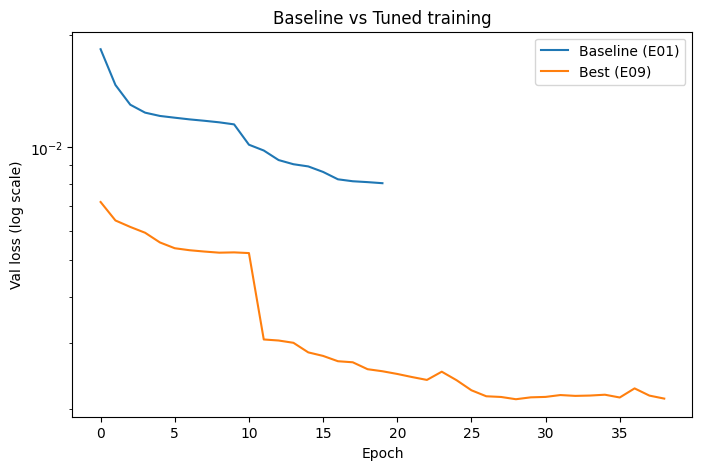

In [21]:
# 3) Val loss curve: baseline (E01) vs best model
plt.figure(figsize=(8, 5))
plt.plot(histories["E01"]["val_loss"], label="Baseline (E01)")
plt.plot(histories[best["ID"]]["val_loss"], label=f"Best ({best['ID']})")
plt.yscale("log")
plt.xlabel("Epoch")
plt.ylabel("Val loss (log scale)")
plt.title("Baseline vs Tuned training")
plt.legend()
plt.savefig("results/plots/baseline_vs_tuned_loss.png", dpi=150, bbox_inches="tight")
plt.show()

1. . Which hyperparameter had the biggest impact on val loss?
Layer sizes. With the same LR and batch, changing the baseline layers (8-4-8) to 16-8-4-8-16 lowered val loss from 0.006003 to 0.002097, Changing the LR from 0.001 to 0.003 , and batch size did not help.

2. Did Early Stopping help? After how many epochs did it stop?
Yes. The baseline trained for 20 epochs and got 0.008027. With Early Stopping, the same model trained for 54 epochs and got 0.007724,So the baseline stopped too early.

3. Did bigger or deeper layers always improve the result?
No. With the same LR and batch, the baseline layers 8-4-8 got 0.006003. The smaller 6-4-6 was worse (0.015027), while the wider 16-4-16 (0.003777) and the deeper 16-8-4-8-16 (0.002097) were better. The deeper model was the best because it compresses the message step by step.

4. Did L2 or Dropout help? Why / why not?
No. None of them beat the best model without regularization (E09: 0.002097). Light L2 got 0.002185, stronger L2 got 0.004816, and Dropout got 0.014767, which is even worse than the baseline (0.008027). The model was not overfitting (702 params, ~791k messages), so regularization only limited it.

5. Which model would you choose, and why?
E09. The baseline had 254 params and a val loss of 0.008027. E09 has 702 params and a val loss of 0.002097.